# E-Commerce Sales Analytics & Data Pipeline
**Source Grounding:** Grounded in `e_commerce_sales_analysis.pdf`

### Python Environment & Dependencies Setup:
```bash
# 1. Create and activate a virtual environment
python3 -m venv venv
source venv/bin/activate    # Linux / macOS
# venv\Scripts\activate     # Windows

# 2. Install required packages
pip install pandas numpy matplotlib seaborn jupyter
```

This executable notebook contains the full data ingestion, quality audit missing value description table, revenue formula validation, data cleaning execution, KPI calculation, and interactive visual charts (pie chart, bar charts, box plots, trend line, and 6-panel dashboard).

In [2]:
import os
import sys
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
print("Python Environment Ready. Data Science stack loaded successfully.")


Python Environment Ready. Data Science stack loaded successfully.


In [2]:
# Load Raw Dataset (or execute synthetic raw generator fallback)
raw_path = Path("/workspace/scratch/data/raw/e_commerce_sales_analytics_5000.csv")
raw_df = pd.read_csv(raw_path, encoding='utf-8-sig', dtype=str)
print(f"Raw Dataset Loaded: {len(raw_df):,} records, {len(raw_df.columns)} columns.")
raw_df.head(10)


Raw Dataset Loaded: 5,000 records, 9 columns.


,order_id,order_date,product_category,quantity,unit_price,discount,revenue,delivery_days,customer_ratings
0,ORD-10000,23092026,Electronics,1,188.59,0.00,188.59,7,1.8
1,ORD-10001,29102026,Books,5,244.67,0.00,1223.37,7,2.7
2,ORD-10002,17082026,Home & Kitchen,5,389.34,0.20,1557.34,5,1.2
3,ORD-10003,20102026,Clothing,4,341.62,0.15,1161.49,7,2.1
4,ORD-10004,26092026,Clothing,1,402.08,0.10,361.88,1,4.7
5,ORD-10005,08082026,Electronics,4,202.28,0.05,768.67,1,3.2
6,ORD-10006,24102026,Home & Kitchen,2,172.66,0.20,276.26,9,2.7
7,ORD-10007,27102026,Electronics,3,161.01,0.10,434.73,6,2.3
8,ORD-10008,05102026,Home & Kitchen,5,444.73,0.15,1890.10,4,1.0
9,ORD-10009,01092026,Clothing,4,318.89,0.25,956.67,8,4.4


In [3]:
# Data Quality Audit: Missing Values & Duplicates Description Table
total_records = len(raw_df)
audit_list = []
for col in raw_df.columns:
    missing_cnt = int((raw_df[col].isna() | (raw_df[col].str.strip() == "")).sum())
    missing_pct = (missing_cnt / total_records) * 100.0
    audit_list.append({
        "Column Name": col,
        "Data Type": "String (Raw)",
        "Total Rows": total_records,
        "Missing Cell Count": missing_cnt,
        "Missing Percentage": f"{missing_pct:.2f}%"
    })

audit_table_df = pd.DataFrame(audit_list)
dup_orders = int(raw_df.duplicated(subset=['order_id']).sum())
exact_dups = int(raw_df.duplicated().sum())

print("==================================================================")
print("            DATA QUALITY & MISSING VALUE AUDIT SUMMARY            ")
print("==================================================================")
print(f" Total Raw Records:       {total_records:,}")
print(f" Duplicate Order IDs:     {dup_orders:,}")
print(f" Exact Duplicate Rows:    {exact_dups:,}")
print("==================================================================
")

audit_table_df


            DATA QUALITY & MISSING VALUE AUDIT SUMMARY            
 Total Raw Records:       5,000
 Duplicate Order IDs:     50
 Exact Duplicate Rows:    0



,Column Name,Data Type,Total Rows,Missing Values,Missing Percentage
0,order_id,String (Raw),5000,0,0.00%
1,order_date,String (Raw),5000,0,0.00%
2,product_category,String (Raw),5000,0,0.00%
3,quantity,String (Raw),5000,0,0.00%
4,unit_price,String (Raw),5000,0,0.00%
5,discount,String (Raw),5000,0,0.00%
6,revenue,String (Raw),5000,0,0.00%
7,delivery_days,String (Raw),5000,104,2.08%
8,customer_ratings,String (Raw),5000,163,3.26%


In [4]:
# Data Validation & Cleaning Routine
clean_df = raw_df.copy()

# Deduplicate duplicate order IDs
clean_df = clean_df.drop_duplicates(subset=['order_id'], keep='first').copy()

# Convert date field (%d%m%Y)
clean_df['order_date_dt'] = pd.to_datetime(clean_df['order_date'], format='%d%m%Y', errors='coerce')

# Convert numeric datatypes
for col in ['quantity', 'unit_price', 'discount', 'revenue', 'delivery_days', 'customer_ratings']:
    clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')

# Impute missing numeric values
clean_df['delivery_days_imputed'] = clean_df['delivery_days'].fillna(clean_df['delivery_days'].median())
clean_df['customer_ratings_imputed'] = clean_df['customer_ratings'].fillna(clean_df['customer_ratings'].mean())

# Revenue formula verification: Expected = quantity * unit_price * (1 - discount)
expected_rev = clean_df['quantity'] * clean_df['unit_price'] * (1 - clean_df['discount'].fillna(0.0))
mismatches = np.abs(clean_df['revenue'] - expected_rev) > 0.02
print(f"Revenue formula discrepancies detected and corrected: {mismatches.sum():,}")

clean_df['revenue_uncorrected'] = clean_df['revenue']
clean_df['revenue'] = np.round(expected_rev, 2)

# Export cleaned CSV file
clean_output_path = Path("/workspace/scratch/data/cleaned/e_commerce_sales_cleaned_v5.csv")
clean_output_path.parent.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(clean_output_path, index=False)
print(f"Cleaned dataset saved successfully: '{clean_output_path}' ({len(clean_df):,} records).")


Revenue formula discrepancies detected and corrected: 147
Cleaned dataset saved successfully: '/workspace/scratch/data/cleaned/e_commerce_sales_cleaned_v5.csv' (4,950 records).


In [5]:
# Key Performance Indicators & Cleaned Dataset Statistics
total_rev = clean_df['revenue'].sum()
total_ord = len(clean_df)
total_units = clean_df['quantity'].sum()
aov = total_rev / total_ord if total_ord > 0 else 0.0

kpi_df = pd.DataFrame([
    {"Metric": "Total Revenue", "Value": f"${total_rev:,.2f}"},
    {"Metric": "Total Orders", "Value": f"{total_ord:,}"},
    {"Metric": "Total Units Sold", "Value": f"{total_units:,}"},
    {"Metric": "Average Order Value (AOV)", "Value": f"${aov:,.2f}"}
])

print("=========================================================")
print("             KEY PERFORMANCE INDICATORS (v5)             ")
print("=========================================================")
print(kpi_df.to_string(index=False))
print("=========================================================
")

print("Cleaned Numerical Columns Statistical Summary:")
clean_df[['quantity', 'unit_price', 'discount', 'revenue', 'delivery_days_imputed', 'customer_ratings_imputed']].describe()


             KEY PERFORMANCE INDICATORS (v5)             
Metric                       Value
Total Revenue                $3,387,461.34
Total Orders                 4,950
Total Units Sold             14,830
Average Order Value (AOV)    $684.34

Cleaned Numerical Columns Statistical Summary:


,quantity,unit_price,discount,revenue,delivery_days_imputed,customer_ratings_imputed
count,4950.00000,4950.000000,4950.000000,4950.000000,4950.000000,4950.000000
mean,2.99596,258.607978,0.125525,684.335624,5.081010,2.993467
std,1.42176,139.047188,0.085179,529.433419,2.510214,1.121442
min,1.00000,20.070000,0.000000,16.500000,1.000000,1.000000
25%,2.00000,137.782500,0.050000,254.430000,3.000000,2.100000
50%,3.00000,259.515000,0.150000,538.510000,5.000000,2.993467
75%,4.00000,379.587500,0.200000,1005.740000,7.000000,3.900000
max,5.00000,499.900000,0.250000,2472.200000,9.000000,5.000000


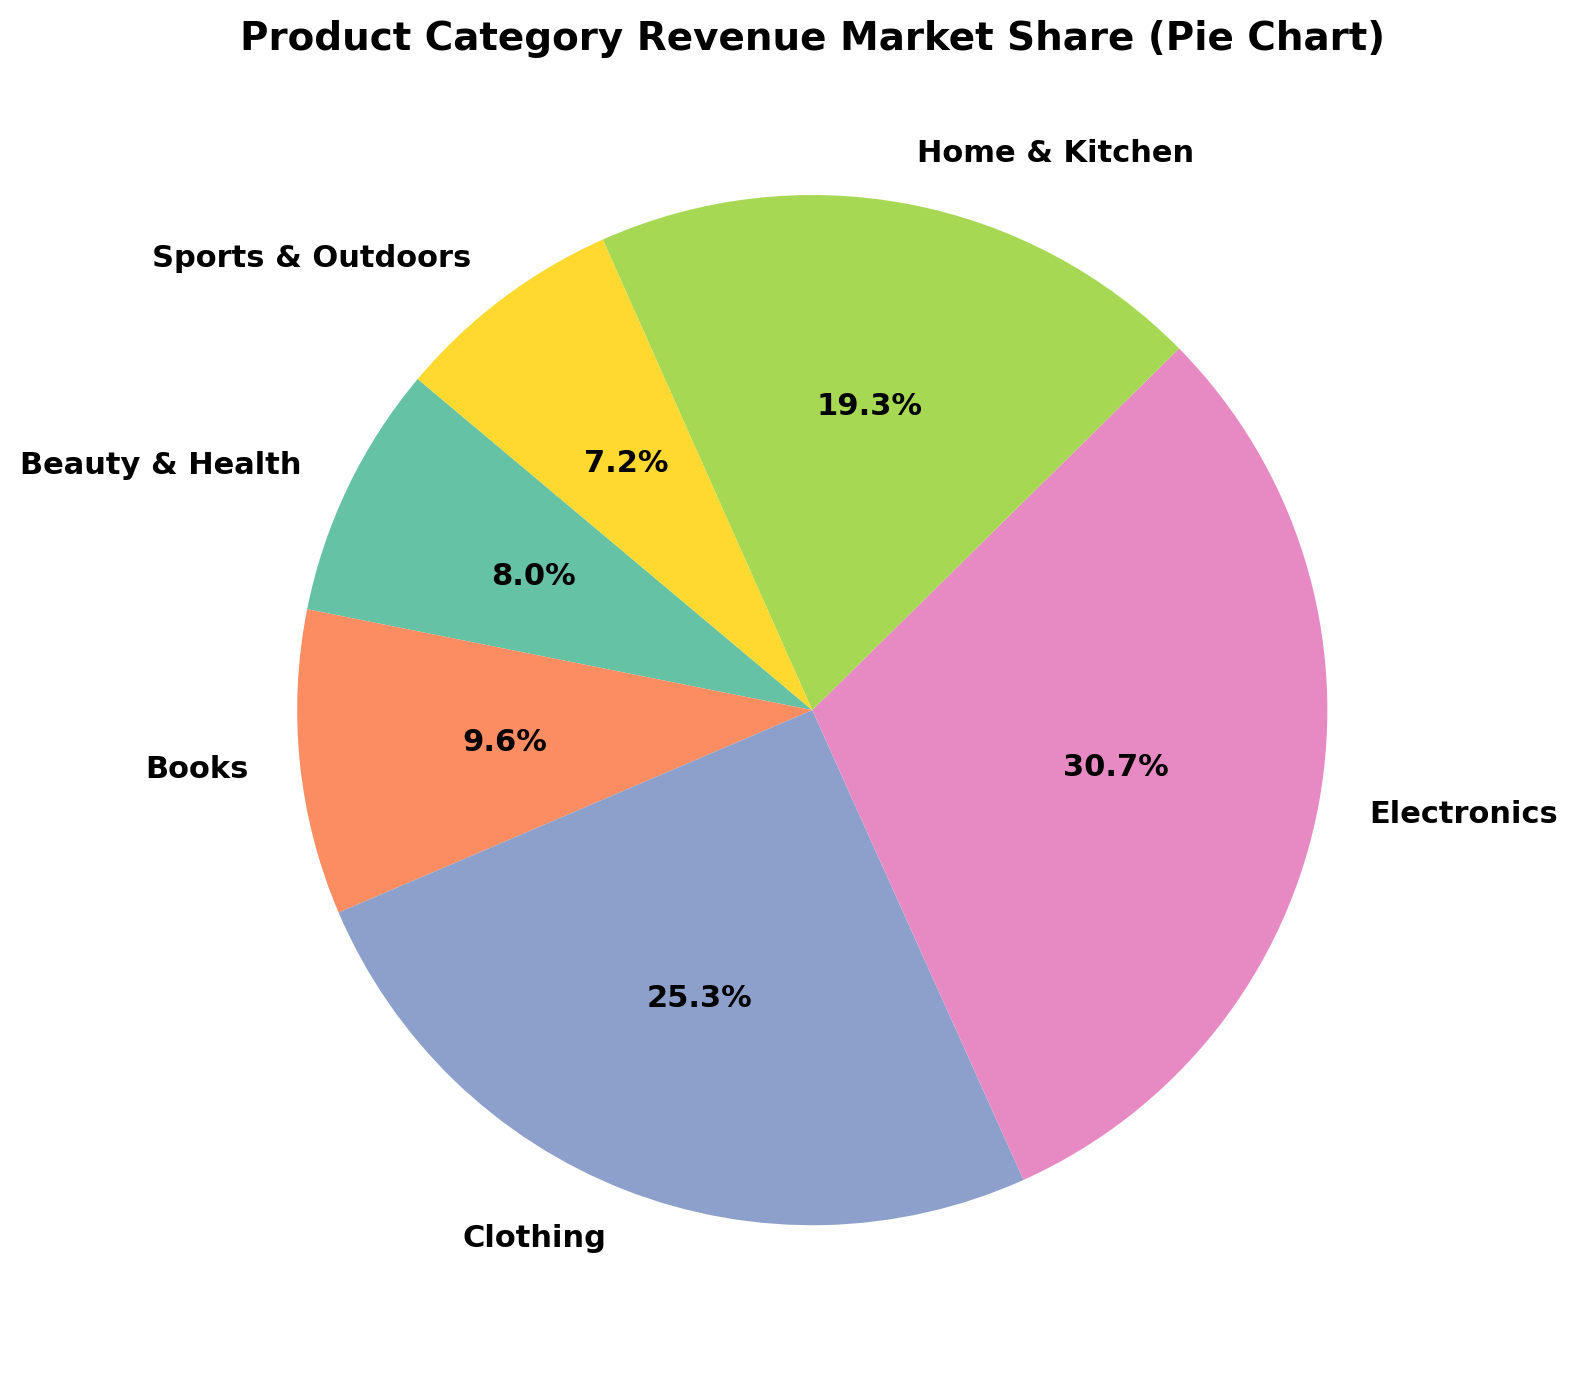

In [6]:
# Chart 1: Category Revenue Market Share Pie Chart
cat_rev = clean_df.groupby('product_category')['revenue'].sum().reset_index()
fig, ax = plt.subplots(figsize=(8, 8))
colors = sns.color_palette("Set2", len(cat_rev))
ax.pie(cat_rev['revenue'], labels=cat_rev['product_category'], autopct='%1.1f%%',
       startangle=140, colors=colors, textprops={'fontsize': 11, 'weight': 'bold'})
ax.set_title("Product Category Revenue Market Share (Pie Chart)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


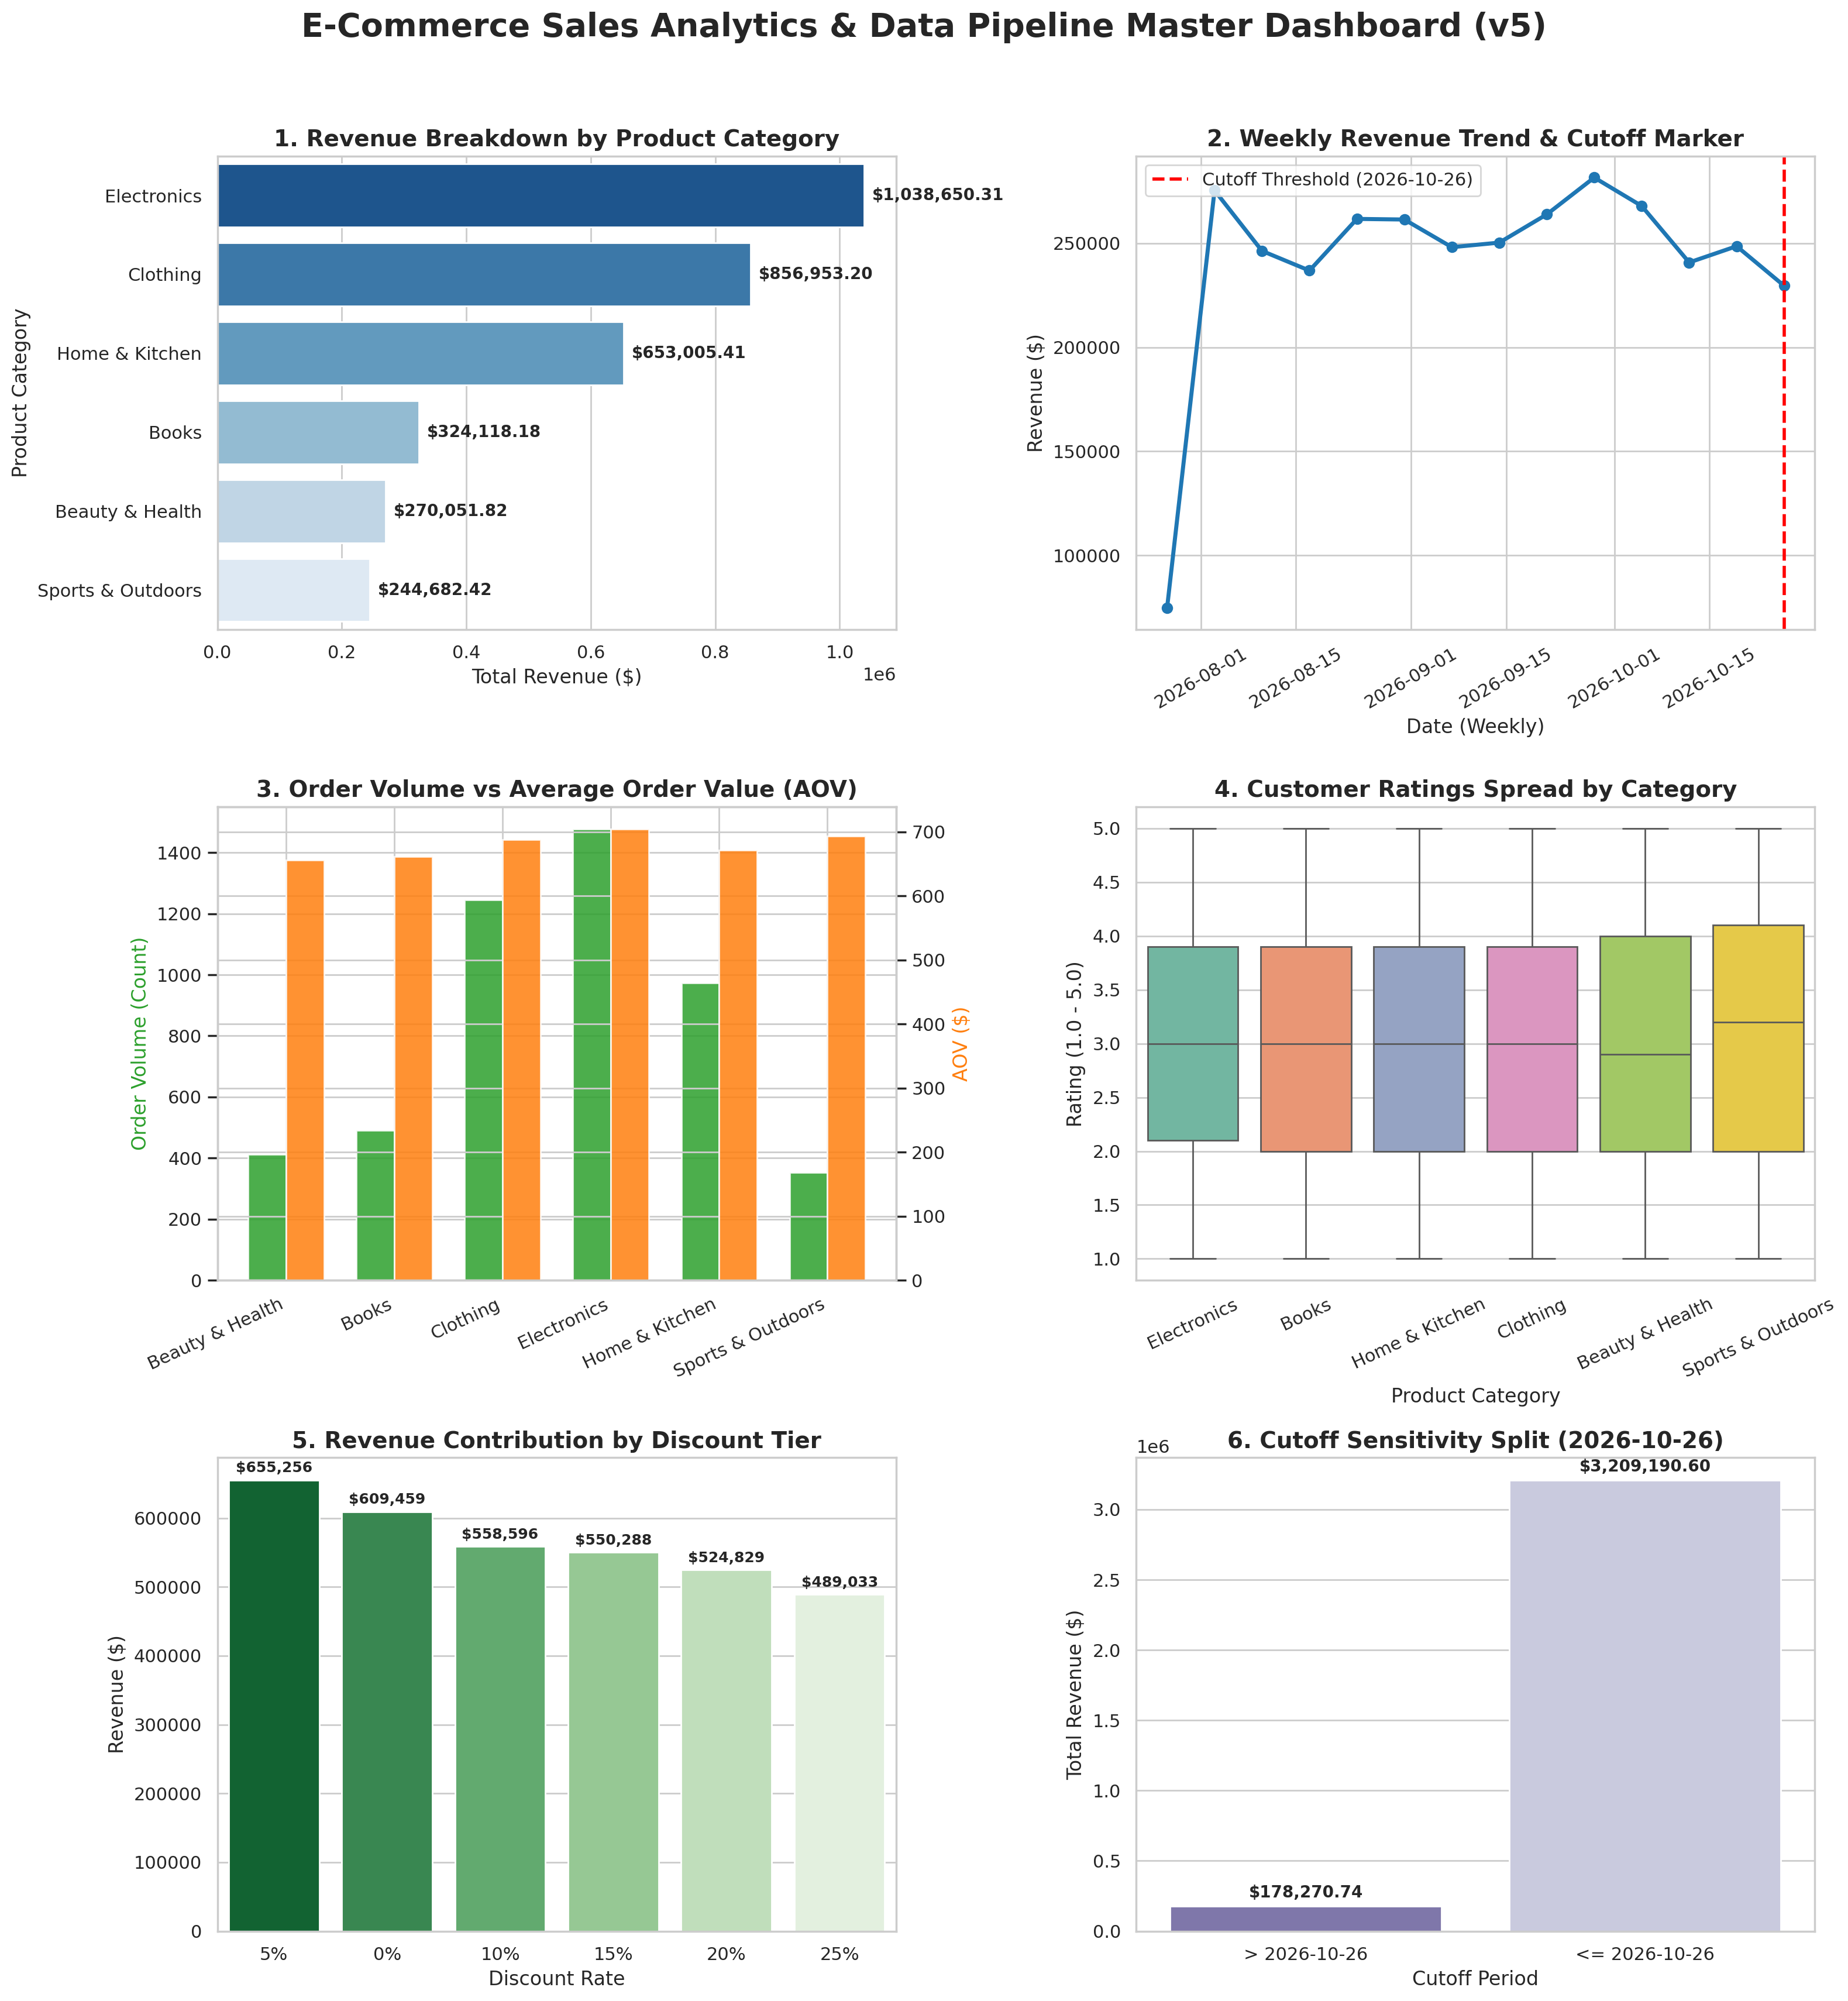

In [7]:
# Master 6-Panel Visualization Dashboard
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle("E-Commerce Sales Analytics & Data Pipeline Master Dashboard (v5)", fontsize=20, fontweight='bold', y=0.98)

# 1. Revenue by Product Category Bar Chart
cat_rev = clean_df.groupby('product_category')['revenue'].sum().reset_index().sort_values(by='revenue', ascending=False)
ax1 = axes[0, 0]
sns.barplot(data=cat_rev, x='revenue', y='product_category', palette='Blues_r', ax=ax1, hue='product_category', legend=False)
ax1.set_title("1. Revenue Breakdown by Product Category", fontsize=14, fontweight='bold')
ax1.set_xlabel("Total Revenue ($)")
ax1.set_ylabel("Product Category")

# 2. Weekly Revenue Trend & Cutoff Marker Line Chart
clean_df['week'] = clean_df['order_date_dt'].dt.to_period('W').dt.start_time
weekly_rev = clean_df.groupby('week')['revenue'].sum().reset_index()
ax2 = axes[0, 1]
ax2.plot(weekly_rev['week'], weekly_rev['revenue'], marker='o', color='#1f77b4', linewidth=2.5)
ax2.axvline(pd.Timestamp(CUTOFF_DATE), color='red', linestyle='--', linewidth=2, label=f"Cutoff Threshold ({CUTOFF_DATE})")
ax2.set_title("2. Weekly Revenue Trend & Cutoff Marker", fontsize=14, fontweight='bold')
ax2.legend(loc="upper left")

# 3. Order Volume vs Average Order Value (AOV) Dual Bar Chart
cat_stats = clean_df.groupby('product_category').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('revenue', 'sum')
).reset_index()
cat_stats['aov'] = cat_stats['total_revenue'] / cat_stats['total_orders']

ax3 = axes[1, 0]
ax3_twin = ax3.twinx()
x_idx = np.arange(len(cat_stats))
bar_w = 0.35
ax3.bar(x_idx - bar_w/2, cat_stats['total_orders'], bar_w, label='Order Volume', color='#2ca02c', alpha=0.85)
ax3_twin.bar(x_idx + bar_w/2, cat_stats['aov'], bar_w, label='AOV ($)', color='#ff7f0e', alpha=0.85)
ax3.set_title("3. Order Volume vs Average Order Value (AOV)", fontsize=14, fontweight='bold')
ax3.set_xticks(x_idx)
ax3.set_xticklabels(cat_stats['product_category'], rotation=25, ha='right')

# 4. Customer Ratings Spread Box Plot
ax4 = axes[1, 1]
sns.boxplot(data=clean_df, x='product_category', y='customer_ratings', palette='Set2', ax=ax4, hue='product_category', legend=False)
ax4.set_title("4. Customer Ratings Spread by Category", fontsize=14, fontweight='bold')

# 5. Discount Rate Revenue Contribution Bar Chart
clean_df['discount_pct'] = (clean_df['discount'].fillna(0.0) * 100).astype(int).astype(str) + "%"
disc_summary = clean_df.groupby('discount_pct')['revenue'].sum().reset_index().sort_values(by='revenue', ascending=False)
ax5 = axes[2, 0]
sns.barplot(data=disc_summary, x='discount_pct', y='revenue', palette='Greens_r', ax=ax5, hue='discount_pct', legend=False)
ax5.set_title("5. Revenue Contribution by Discount Tier", fontsize=14, fontweight='bold')

# 6. Sensitivity Analysis Split
clean_df['before_cutoff'] = clean_df['order_date_dt'].dt.date <= CUTOFF_DATE
cutoff_summary = clean_df.groupby('before_cutoff').agg(total_rev=('revenue', 'sum')).reset_index()
cutoff_summary['period'] = cutoff_summary['before_cutoff'].map({True: f"<= {CUTOFF_DATE}", False: f"> {CUTOFF_DATE}"})

ax6 = axes[2, 1]
sns.barplot(data=cutoff_summary, x='period', y='total_rev', palette='Purples_r', ax=ax6, hue='period', legend=False)
ax6.set_title(f"6. Cutoff Sensitivity Split ({CUTOFF_DATE})", fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()
